In [14]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
import seaborn as sns
from config import config
import torch
import os
import glob
from PIL import Image, ImageDraw, ImageFont
import torchvision.transforms as T
from model_congelado import AgeEstimationModel as AgeEstimationModelCongelado
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [16]:
import torchvision.transforms as transforms
def inference(model, image_path, output_path):
    model.eval() 
    with torch.no_grad():
        image = Image.open(image_path).convert('RGB')
        transform = T.Compose([T.Resize(((config['img_width'], config['img_height']))),
                               T.ToTensor(),
                               T.Normalize(mean=config['mean'], 
                                           std=config['std'])
                              ])
        input_data = transform(image).unsqueeze(0).to(config['device']) 
        outputs = model(input_data)  # Forward pass through the model
        
        # Extract the age estimation value from the output tensor
        age_estimation = outputs.item()
        """
        # Create a PIL image with the age estimation value as text
        output_image = image.copy()
        draw = ImageDraw.Draw(output_image)
        text = f"Age: {age_estimation:.2f}"  
        draw.text((10, 10), text, fill=(255, 0, 0))
        print(f"Age estimation: {age_estimation:.2f}")
        
        # Save the output image
        output_image.save(output_path)
        """
        return age_estimation

In [13]:
# Modelo Congelado

# Dados los pesos de mi modelo, lo cargo, y hago la prediccion de todo el test. Quiero medir el error que obtengo en el test.
path = "/home/anacotler/Documents/vision_artificial/tpf_vision/checkpoints"
path = "/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/checkpoints"
checkpoint_files = '/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/checkpoints/18EPOCHSALL_epoch-0-loss_valid-5.51.pt'
model = AgeEstimationModelCongelado(input_dim=3, output_nodes=1, model_name=config['model_name'], pretrain_weights='IMAGENET1K_V2').to(config['device'])
model.load_state_dict(torch.load(checkpoint_files, weights_only=True))
# path_csv_dataset = '/home/anacotler/Documents/vision_artificial/tpf_vision/csv_dataset/test_set.csv'
path_csv_dataset = '/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/csv_dataset/test_set.csv'
df = pd.read_csv(path_csv_dataset)
df['age'] = df['age'].astype(np.float32)

# Hacer la prediccion de todo el test
output_path = ''
reales = []
predicciones = []
outliers_real = []
outliers_pred = []

for i in range(len(df)):
    image_path = '/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/utkcropped/'+df['image_name'][i]
    age = df['age'][i]
    prediction = inference(model, image_path, output_path)

    # Ajustar la prediccion a numeros enteros
    if prediction < 1 and prediction > 0:
        prediction = 1
    elif prediction < 0:
        prediction = 0
    elif prediction > 100:
        prediction = 100
    else:
        prediction = round(prediction)
    
    if np.abs(age - prediction) > 10:
        #print(f"Real: {age}, Predicción: {prediction}")
        #print(f"Image: {image_path}")
        #print('')
        outliers_real.append(age)
        outliers_pred.append(prediction)


    reales.append(age)
    predicciones.append(prediction)

reales = np.array(reales)
predicciones = np.array(predicciones)

# Que los valores sean enteros
reales = reales.astype(int)
predicciones = predicciones.astype(int)


# Calcular los errores
errores = predicciones - reales
errores = errores.astype(int)

# Crear un DataFrame con los datos
df_errores = pd.DataFrame({'Real': reales, 'Error': errores})

# Crear los boxplots por cada edad
plt.figure(figsize=(12, 6))
sns.boxplot(x='Real', y='Error', data=df_errores)
plt.axhline(0, color='red', linestyle='--')  # Línea de referencia en 0
plt.xlabel('Edad Real')
plt.ylabel('Error (Predicción - Real)')
plt.title('Distribución del Error por Edad Real')
plt.xticks(rotation=45)
plt.show()


KeyboardInterrupt: 

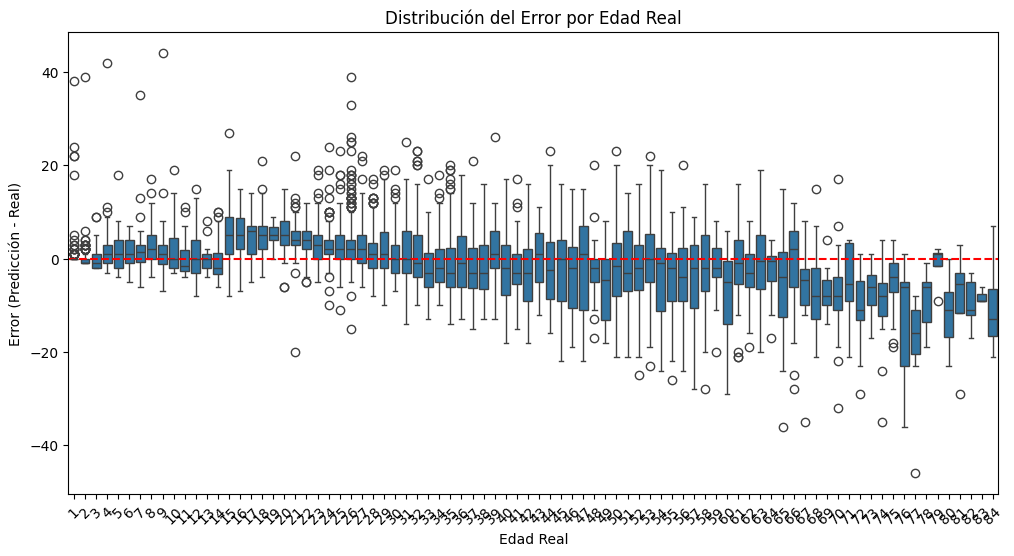

In [17]:
from model_arista import AgeEstimationModel as AgeEstimationModelArista

# Modelo Arista 
# Dados los pesos de mi modelo, lo cargo, y hago la prediccion de todo el test. Quiero medir el error que obtengo en el test.
path = "/home/anacotler/Documents/vision_artificial/tpf_vision/checkpoints"
path = "/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/checkpoints"
checkpoint_files = '/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/checkpoints/capa_epoch-45-loss_valid-4.97.pt'
model = AgeEstimationModelArista(input_dim=3, output_nodes=1, model_name=config['model_name'], pretrain_weights='IMAGENET1K_V2').to(config['device'])
model.load_state_dict(torch.load(checkpoint_files, weights_only=True))
# path_csv_dataset = '/home/anacotler/Documents/vision_artificial/tpf_vision/csv_dataset/test_set.csv'
path_csv_dataset = '/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/csv_dataset/test_set.csv'
df = pd.read_csv(path_csv_dataset)
df['age'] = df['age'].astype(np.float32)

# Hacer la prediccion de todo el test
output_path = ''
reales = []
predicciones = []
outliers_real = []
outliers_pred = []

for i in range(len(df)):
    image_path = '/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/utkcropped/'+df['image_name'][i]
    age = df['age'][i]
    prediction = inference(model, image_path, output_path)

    # Ajustar la prediccion a numeros enteros
    if prediction < 1 and prediction > 0:
        prediction = 1
    elif prediction < 0:
        prediction = 0
    elif prediction > 100:
        prediction = 100
    else:
        prediction = round(prediction)
    
    if np.abs(age - prediction) > 10:
        #print(f"Real: {age}, Predicción: {prediction}")
        #print(f"Image: {image_path}")
        #print('')
        outliers_real.append(age)
        outliers_pred.append(prediction)


    reales.append(age)
    predicciones.append(prediction)

reales = np.array(reales)
predicciones = np.array(predicciones)

# Que los valores sean enteros
reales = reales.astype(int)
predicciones = predicciones.astype(int)


# Calcular los errores
errores = predicciones - reales
errores = errores.astype(int)

# Crear un DataFrame con los datos
df_errores = pd.DataFrame({'Real': reales, 'Error': errores})

# Crear los boxplots por cada edad
plt.figure(figsize=(12, 6))
sns.boxplot(x='Real', y='Error', data=df_errores)
plt.axhline(0, color='red', linestyle='--')  # Línea de referencia en 0
plt.xlabel('Edad Real')
plt.ylabel('Error (Predicción - Real)')
plt.title('Distribución del Error por Edad Real')
plt.xticks(rotation=45)
# Guardar la figura con fondo transparente
plt.savefig('boxplot_arista.png', transparent=True)
plt.show()
